In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print("House Price Prediction Project")

House Price Prediction Project


In [3]:
import pandas as pd

df = pd.read_csv("AmesHousing.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 2930
Columns: 7


In [4]:
print(df.columns.tolist())

['BsmtFin SF 1', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Gr Liv Area', 'SalePrice']


In [5]:
df.head()

,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Gr Liv Area,SalePrice
0,639.0,441.0,1080.0,1656,0,1656,215000
1,468.0,270.0,882.0,896,0,896,105000
2,923.0,406.0,1329.0,1329,0,1329,172000
3,1065.0,1045.0,2110.0,2110,0,2110,244000
4,791.0,137.0,928.0,928,701,1629,189900


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BsmtFin SF 1   2929 non-null   float64
 1   Bsmt Unf SF    2929 non-null   float64
 2   Total Bsmt SF  2929 non-null   float64
 3   1st Flr SF     2930 non-null   int64  
 4   2nd Flr SF     2930 non-null   int64  
 5   Gr Liv Area    2930 non-null   int64  
 6   SalePrice      2930 non-null   int64  
dtypes: float64(3), int64(4)
memory usage: 160.4 KB


In [7]:
df.describe()

,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Gr Liv Area,SalePrice
count,2929.000000,2929.000000,2929.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,442.629566,559.262547,1051.614544,1159.557679,335.455973,1499.690444,180796.060068
std,455.590839,439.494153,440.615067,391.890885,428.395715,505.508887,79886.692357
min,0.000000,0.000000,0.000000,334.000000,0.000000,334.000000,12789.000000
25%,0.000000,219.000000,793.000000,876.250000,0.000000,1126.000000,129500.000000
50%,370.000000,466.000000,990.000000,1084.000000,0.000000,1442.000000,160000.000000
75%,734.000000,802.000000,1302.000000,1384.000000,703.750000,1742.750000,213500.000000
max,5644.000000,2336.000000,6110.000000,5095.000000,2065.000000,5642.000000,755000.000000


In [8]:
df.isnull().sum()

BsmtFin SF 1     1
Bsmt Unf SF      1
Total Bsmt SF    1
1st Flr SF       0
2nd Flr SF       0
Gr Liv Area      0
SalePrice        0
dtype: int64

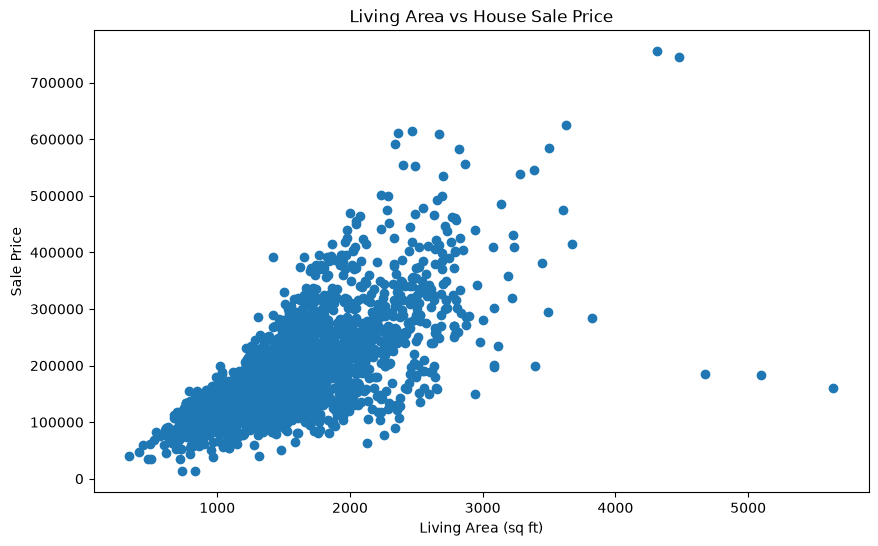

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(df["Gr Liv Area"], df["SalePrice"])

plt.xlabel("Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Living Area vs House Sale Price")

plt.show()

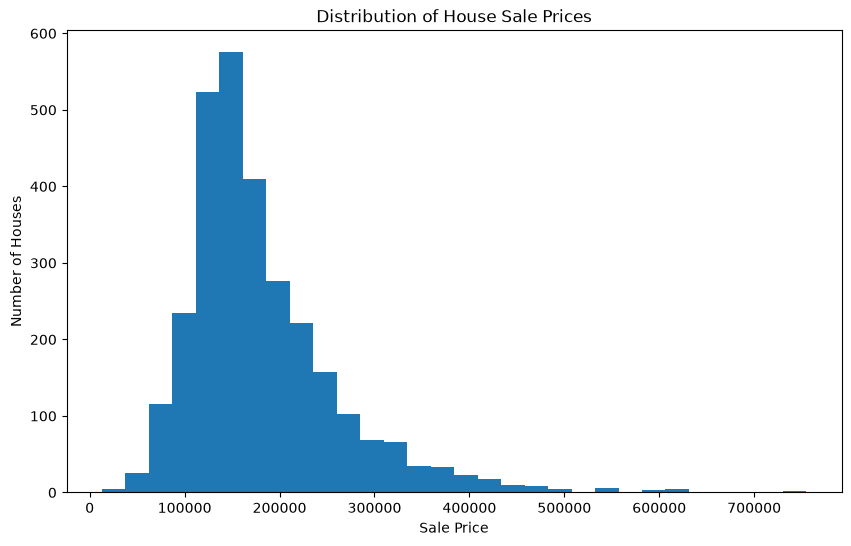

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(df["SalePrice"], bins=30)

plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Sale Prices")

plt.show()

In [11]:
correlation = df.corr(numeric_only=True)

print(correlation["SalePrice"].sort_values(ascending=False))

SalePrice        1.000000
Gr Liv Area      0.706780
Total Bsmt SF    0.632280
1st Flr SF       0.621676
BsmtFin SF 1     0.432914
2nd Flr SF       0.269373
Bsmt Unf SF      0.182855
Name: SalePrice, dtype: float64


In [12]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   BsmtFin SF 1  Bsmt Unf SF  Total Bsmt SF  1st Flr SF  2nd Flr SF  \
0         639.0        441.0         1080.0        1656           0   
1         468.0        270.0          882.0         896           0   
2         923.0        406.0         1329.0        1329           0   
3        1065.0       1045.0         2110.0        2110           0   
4         791.0        137.0          928.0         928         701   

   Gr Liv Area  
0         1656  
1          896  
2         1329  
3         2110  
4         1629  

Target (y):
0    215000
1    105000
2    172000
3    244000
4    189900
Name: SalePrice, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2344
Testing samples: 586


In [15]:
print(df.isnull().sum())

BsmtFin SF 1     1
Bsmt Unf SF      1
Total Bsmt SF    1
1st Flr SF       0
2nd Flr SF       0
Gr Liv Area      0
SalePrice        0
dtype: int64


In [16]:
df = df.dropna().copy()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nNew dataset shape:", df.shape)

Missing values after cleaning:
BsmtFin SF 1     0
Bsmt Unf SF      0
Total Bsmt SF    0
1st Flr SF       0
2nd Flr SF       0
Gr Liv Area      0
SalePrice        0
dtype: int64

New dataset shape: (2929, 7)


In [17]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2343
Testing samples: 586


In [18]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [19]:
y_pred = linear_model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[196903.1563111  159694.31192127 239131.75698967 235263.22556164
 135367.97030301  82209.31425501 204976.26674573 202121.71310648
 149097.07343352 251491.09480974]


In [20]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.4870435241774468


In [21]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 31711.836984816327


In [22]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 61823.20959708743


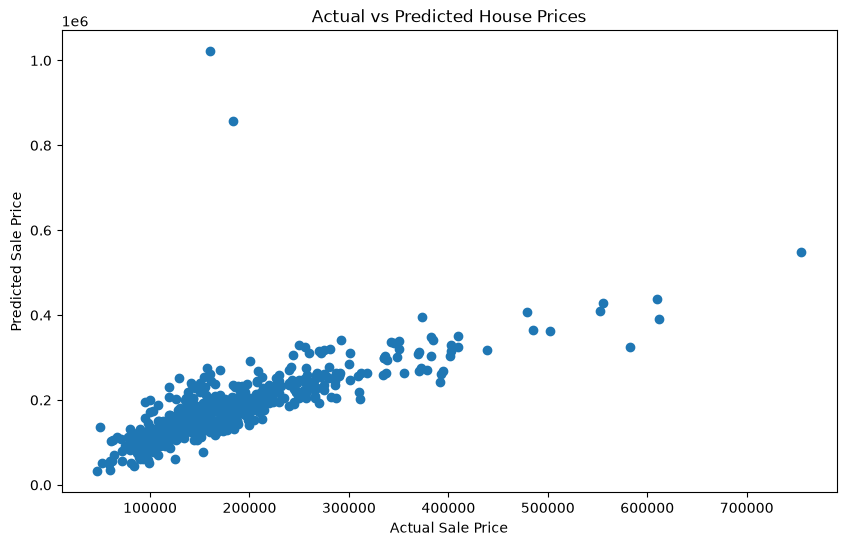

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [25]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [26]:
rf_pred = rf_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(rf_pred[:10])

First 10 Random Forest predictions:
[213039.605 154920.92  251380.8   208038.62  131192.75   83465.13
 196220.745 186313.255 145946.    228984.89 ]


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 27023.89307435459
Random Forest RMSE: 41112.89046241412
Random Forest R²: 0.773152789508916


In [28]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R²": [r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R²
0,Linear Regression,31711.836985,61823.209597,0.487044
1,Random Forest,27023.893074,41112.890462,0.773153


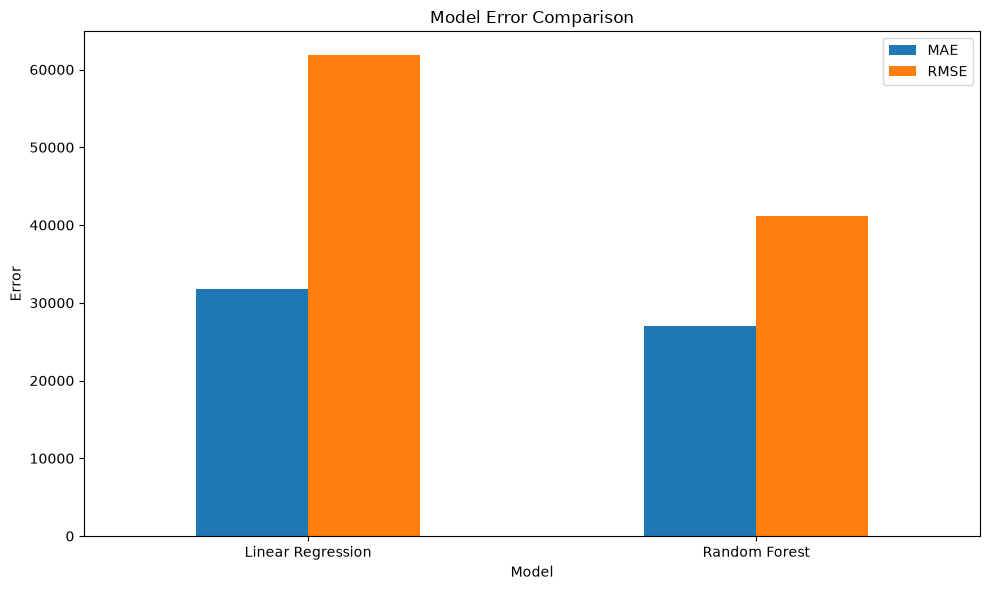

In [29]:
comparison.plot(
    x="Model",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
5,Gr Liv Area,0.390473
2,Total Bsmt SF,0.323523
0,BsmtFin SF 1,0.110932
4,2nd Flr SF,0.073627
1,Bsmt Unf SF,0.055443
3,1st Flr SF,0.046002


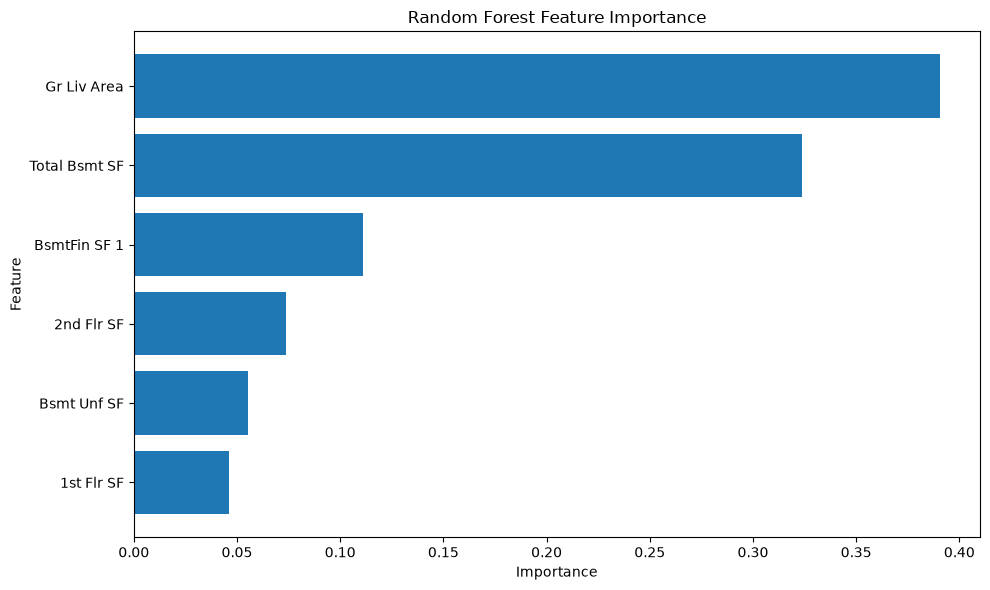

In [31]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [32]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

print("Gradient Boosting model created successfully!")

Gradient Boosting model created successfully!


In [33]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [34]:
gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting MAE: 25572.99781434433
Gradient Boosting RMSE: 37673.67367992058
Gradient Boosting R²: 0.8095182535446355


In [35]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse,
        gb_rmse
    ],
    "R²": [
        r2,
        rf_r2,
        gb_r2
    ]
})

comparison

,Model,MAE,RMSE,R²
0,Linear Regression,31711.836985,61823.209597,0.487044
1,Random Forest,27023.893074,41112.890462,0.773153
2,Gradient Boosting,25572.997814,37673.673680,0.809518


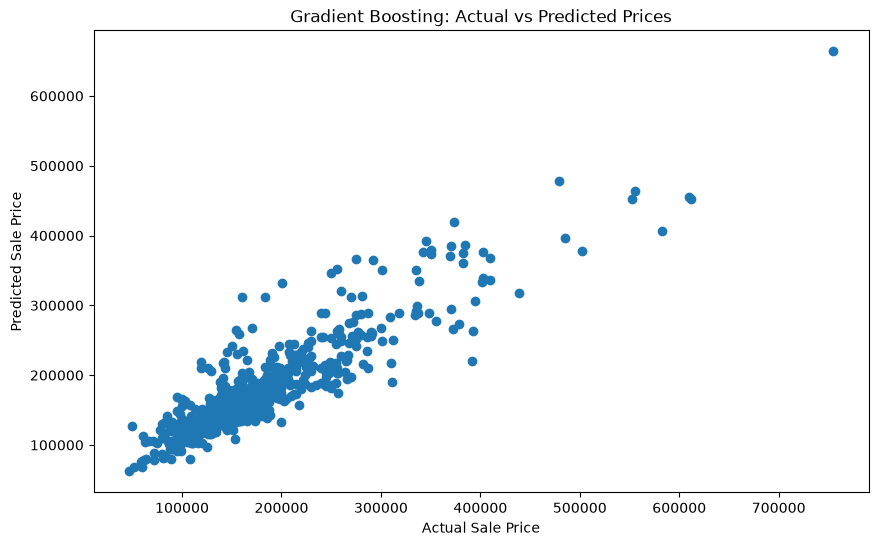

In [36]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, gb_pred)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Gradient Boosting: Actual vs Predicted Prices")

plt.show()

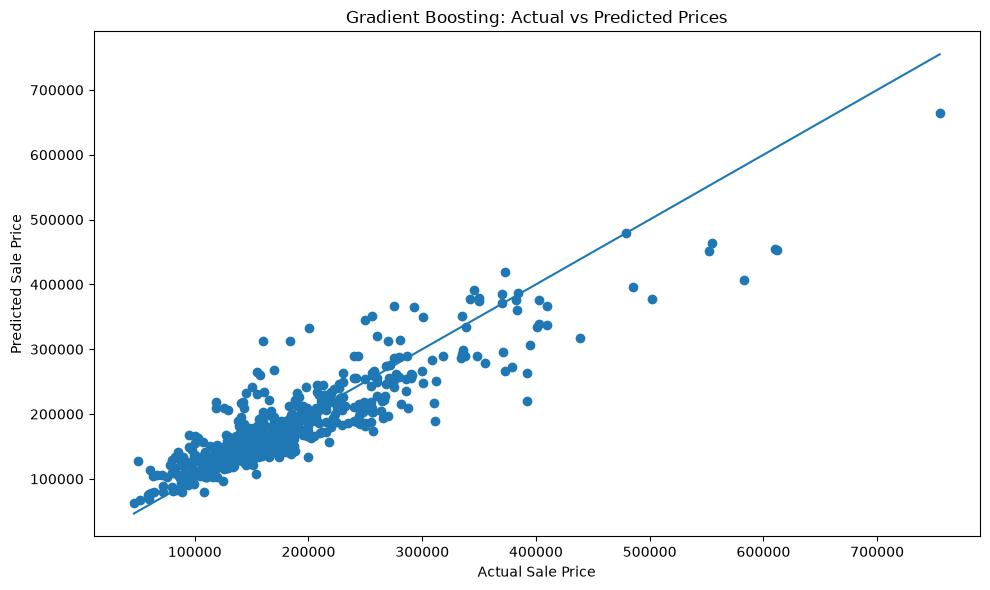

In [37]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, gb_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Gradient Boosting: Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

In [38]:
error_analysis = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": gb_pred
})

error_analysis["Error"] = (
    error_analysis["Actual Price"] -
    error_analysis["Predicted Price"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Error"].abs()
)

error_analysis.head()

,Actual Price,Predicted Price,Error,Absolute Error
0,208500,205266.513866,3233.486134,3233.486134
1,171500,151573.747601,19926.252399,19926.252399
2,260000,248735.614190,11264.385810,11264.385810
3,183000,211950.483117,-28950.483117,28950.483117
4,132500,128738.918569,3761.081431,3761.081431


In [39]:
largest_errors = error_analysis.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

largest_errors

,Actual Price,Predicted Price,Error,Absolute Error
445,582933,406289.398357,176643.601643,176643.601643
368,392000,219695.917819,172304.082181,172304.082181
169,611657,452348.425674,159308.574326,159308.574326
504,610000,454686.402884,155313.597116,155313.597116
339,160000,312488.093917,-152488.093917,152488.093917
448,200500,332200.317670,-131700.317670,131700.317670
288,392500,263838.982987,128661.017013,128661.017013
232,183850,312400.305031,-128550.305031,128550.305031
201,501837,377304.263585,124532.736415,124532.736415
467,311500,189548.864576,121951.135424,121951.135424


In [40]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    gb_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:")
print(cv_scores)

print("\nMean Cross-validation R²:", cv_scores.mean())

Cross-validation R² scores:
[0.75590048 0.74446666 0.74004107 0.59018565 0.70377047]

Mean Cross-validation R²: 0.7068728664914117


In [41]:
comparison

,Model,MAE,RMSE,R²
0,Linear Regression,31711.836985,61823.209597,0.487044
1,Random Forest,27023.893074,41112.890462,0.773153
2,Gradient Boosting,25572.997814,37673.673680,0.809518


In [42]:
def predict_house_price(
    bsmt_fin_sf1,
    bsmt_unf_sf,
    total_bsmt_sf,
    first_flr_sf,
    second_flr_sf,
    gr_liv_area
):
    house = pd.DataFrame({
        "BsmtFin SF 1": [bsmt_fin_sf1],
        "Bsmt Unf SF": [bsmt_unf_sf],
        "Total Bsmt SF": [total_bsmt_sf],
        "1st Flr SF": [first_flr_sf],
        "2nd Flr SF": [second_flr_sf],
        "Gr Liv Area": [gr_liv_area]
    })

    prediction = gb_model.predict(house)

    return prediction[0]

In [43]:
predicted_price = predict_house_price(
    bsmt_fin_sf1=800,
    bsmt_unf_sf=300,
    total_bsmt_sf=1100,
    first_flr_sf=1200,
    second_flr_sf=800,
    gr_liv_area=2000
)

print("Estimated House Sale Price: $", round(predicted_price, 2))

Estimated House Sale Price: $ 229246.59


In [44]:
print("🏠 House Price Prediction")
print("-" * 35)

print(f"Estimated Sale Price: ${predicted_price:,.2f}")

🏠 House Price Prediction
-----------------------------------
Estimated Sale Price: $229,246.59


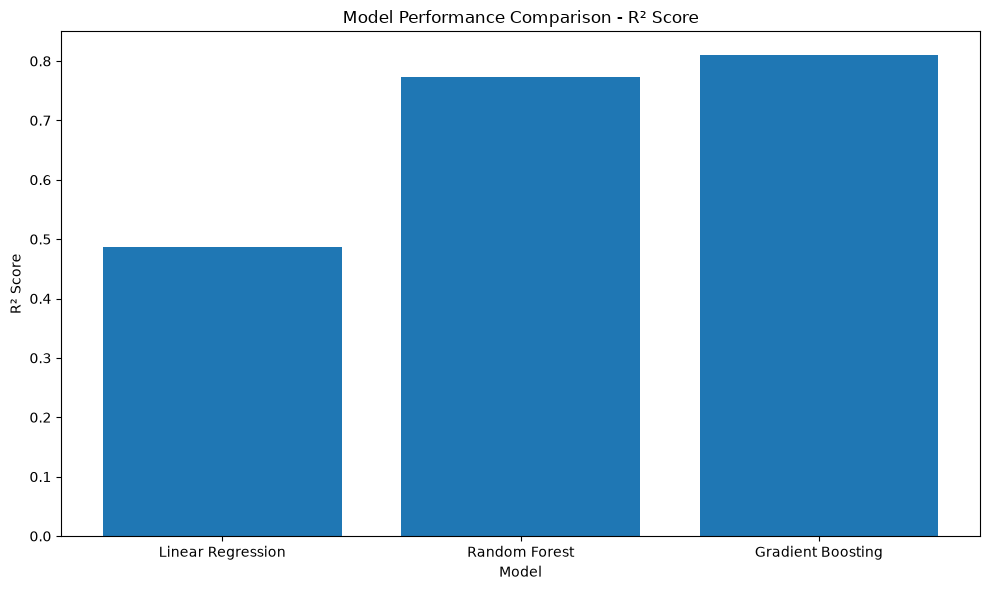

In [45]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["R²"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Model Performance Comparison - R² Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

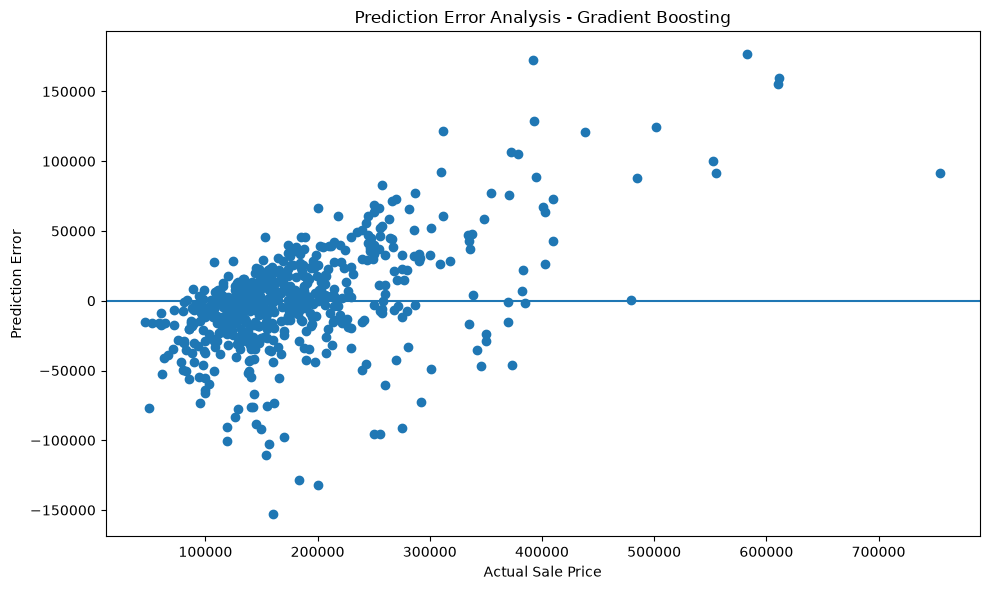

In [46]:
plt.figure(figsize=(10, 6))

plt.scatter(
    error_analysis["Actual Price"],
    error_analysis["Error"]
)

plt.axhline(y=0)

plt.xlabel("Actual Sale Price")
plt.ylabel("Prediction Error")
plt.title("Prediction Error Analysis - Gradient Boosting")
plt.tight_layout()
plt.show()

In [47]:
import joblib

joblib.dump(gb_model, "house_price_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [48]:
print("🏠 HOUSE PRICE PREDICTION PROJECT")
print("=" * 45)

print("Dataset: Ames Housing Dataset")
print("Features used:", X.shape[1])
print("Target: SalePrice")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModels trained:")
print("1. Linear Regression")
print("2. Random Forest Regressor")
print("3. Gradient Boosting Regressor")

print("\nEvaluation metrics:")
print("- MAE")
print("- RMSE")
print("- R² Score")

print("\nFinal model: Gradient Boosting Regressor")
print("Saved as: house_price_model.pkl")

🏠 HOUSE PRICE PREDICTION PROJECT
Dataset: Ames Housing Dataset
Features used: 6
Target: SalePrice
Training samples: 2343
Testing samples: 586

Models trained:
1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

Evaluation metrics:
- MAE
- RMSE
- R² Score

Final model: Gradient Boosting Regressor
Saved as: house_price_model.pkl
